## 1. Import Packages

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import kagglehub

## 2. Load Skincare Product Data

### 2.1 Download Dataset

In [ ]:
# Download dataset from Kaggle directly
DATA_DIR = kagglehub.dataset_download(
    handle="nadyinky/sephora-products-and-skincare-reviews",
    output_dir="/content/sephora-products-and-skincare-reviews"
    )

print("Path to dataset files:", DATA_DIR)

PRODUCT_PATH = DATA_DIR + "/product_info.csv"

raw_product = pd.read_csv(PRODUCT_PATH)
df_skincare = raw_product[raw_product["primary_category"] == "Skincare"]
df_skincare.head()

Using Colab cache for faster access to the 'sephora-products-and-skincare-reviews' dataset.
Path to dataset files: /kaggle/input/sephora-products-and-skincare-reviews


,product_id,product_name,brand_id,brand_name,loves_count,rating,reviews,size,variation_type,variation_value,...,online_only,out_of_stock,sephora_exclusive,highlights,primary_category,secondary_category,tertiary_category,child_count,child_max_price,child_min_price
89,P439055,GENIUS Sleeping Collagen Moisturizer,6018,Algenist,33910,4.5413,1321.0,2 oz/ 60 mL,Size,2 oz/ 60 mL,...,0,0,1,"['Vegan', 'Good for: Loss of firmness', 'Colla...",Skincare,Moisturizers,Moisturizers,0,NaN,NaN
90,P421277,GENIUS Liquid Collagen Serum,6018,Algenist,67870,4.0259,1159.0,1 oz / 30 mL,Size,1 oz / 30 mL,...,0,0,1,"['Vegan', 'Good for: Loss of firmness', 'Colla...",Skincare,Treatments,Face Serums,1,25.0,25.0
91,P467602,Triple Algae Eye Renewal Balm Eye Cream,6018,Algenist,17890,4.5306,1142.0,NaN,NaN,NaN,...,0,0,1,NaN,Skincare,Eye Care,Eye Creams & Treatments,0,NaN,NaN
92,P432045,GENIUS Liquid Collagen Lip Treatment,6018,Algenist,44448,3.8721,649.0,.5 oz / 15 mL,Size,.5 oz / 15 mL,...,0,0,1,"['Vegan', 'Good for: Loss of firmness', 'Plump...",Skincare,Lip Balms & Treatments,NaN,0,NaN,NaN
93,P311143,SUBLIME DEFENSE Ultra Lightweight UV Defense F...,6018,Algenist,27278,4.4134,508.0,1 oz,Size,1 oz,...,0,0,0,"['Vegan', 'Hypoallergenic', 'UV Protection', '...",Skincare,Sunscreen,Face Sunscreen,0,NaN,NaN


### 2.2 Find Target Data

In [ ]:
df = df_skincare[df_skincare["tertiary_category"].isin(["Face Serums", "Moisturizers"])].copy()
df = df.rename(columns={"tertiary_category": "category"})

print("Products in scope:", len(df))
df["category"].value_counts()

Products in scope: 765


,count
category,
Moisturizers,386
Face Serums,379


### 2.3 Dropping Duplicates and Missing Values

In [ ]:
n0 = len(df)
df = df.dropna(subset=["ingredients", "rating", "reviews"])
n1 = len(df)

print(f"{'Duplicated product_id':<40}:", df["product_id"].duplicated().sum())

df = df.drop_duplicates(subset=["brand_name", "product_name"], keep="first")
n2 = len(df)

df = df[~df["product_name"].str.contains(r"\bmini\b", case=False)]
n3 = len(df)

print(f"{'Dropped - missing ingredients/rating':<40}:", n0 - n1)
print(f"{'Dropped - duplicate brand + name':<40}:", n1 - n2)
print(f"{'Dropped - mini sizes':<40}:", n2 - n3)
print(f"{'Products remaining':<40}:", n3)

Duplicated product_id                   : 0
Dropped - missing ingredients/rating    : 28
Dropped - duplicate brand + name        : 1
Dropped - mini sizes                    : 20
Products remaining                      : 716


### 2.4 Calculate Price per mL

Total price alone can be misleading when products come in different sizes, so we also compute **price per mL** from the `size` column (e.g., `2 oz/ 60 mL` → 60 mL).

- **Coverage:** only sizes listed in mL can be parsed. Products listed only in oz or other units keep a missing (`NaN`) value. They are not dropped or imputed, so they stay in every other analysis.
- **Where it is used:** Q1 only, as a descriptive check (price-per-mL summary, boxplot, and its correlation with rating). It also appears as a reference column in the Q3 comparison table.
- **Where it is not used:** price tiers, the Q2 ingredient comparison, and the Q3 screening and ranking all rely on total price (`price_usd`).

In [ ]:
df["size_ml"] = df["size"].str.lower().str.extract(r"([\d.]+)\s*ml")[0].astype(float)
df["price_per_ml"] = df["price_usd"] / df["size_ml"]

print("Products with a size in mL:", df["size_ml"].notna().sum(), "of", len(df))
df[["product_name", "size", "size_ml", "price_usd", "price_per_ml"]].head()

Products with a size in mL: 657 of 716


,product_name,size,size_ml,price_usd,price_per_ml
89,GENIUS Sleeping Collagen Moisturizer,2 oz/ 60 mL,60.0,98.0,1.633333
90,GENIUS Liquid Collagen Serum,1 oz / 30 mL,30.0,115.0,3.833333
94,GENIUS Ultimate Anti-Aging Cream,2 oz/ 60 mL,60.0,112.0,1.866667
99,Overnight Restorative Cream,2 oz/ 60 mL,60.0,94.0,1.566667
100,GENIUS Ultimate Anti-Aging Vitamin C+ Serum,1 oz/ 30 mL,30.0,118.0,3.933333


### 2.5 Inspect Price Outliers

Before comparing products, we check for unusually high prices using the standard **IQR rule**. Within each category, a product is flagged as an outlier if its price is above:

> Q3 + 1.5 × (Q3 − Q1)

where Q1 and Q3 are the 25th and 75th percentiles of price in that category. We only flag the high end, since the lowest prices (about 6–8 USD) are plausible for budget products.

The flagged products are **inspected but not removed**. They are mostly genuine luxury items (e.g., La Mer, SK-II, Augustinus Bader) rather than data errors or bundles, and they are exactly the kind of high-priced products we want to find alternatives for. Medians and rank-based (Spearman) correlations are used where outliers could otherwise distort the results, and the outlier flag is not used in later steps.

In [ ]:
df["price_outlier"] = df.groupby("category")["price_usd"].transform(
    lambda x: x > x.quantile(0.75) + 1.5 * (x.quantile(0.75) - x.quantile(0.25))
)

print(df.groupby("category")["price_outlier"].sum())
df[df["price_outlier"]].sort_values("price_usd", ascending=False)[
    ["brand_name", "product_name", "category", "price_usd", "size"]].head(10)

category
Face Serums     21
Moisturizers    32
Name: price_outlier, dtype: int64


,brand_name,product_name,category,price_usd,size
4313,La Mer,The Concentrate Serum,Face Serums,425.0,1 oz/ 30 mL
4320,La Mer,The Regenerating Serum,Face Serums,410.0,1 oz/ 30 mL
6937,SK-II,Ultimate Revival Cream,Moisturizers,400.0,1.6 oz
418,Augustinus Bader,The Serum with TFC8,Face Serums,390.0,0.5 oz / 15 mL
4323,La Mer,The Moisturizing Soft Cream Moisturizer,Moisturizers,380.0,2 oz / 60 mL
4311,La Mer,Crème de la Mer Moisturizer,Moisturizers,380.0,2 oz/ 60 mL
2070,Dr. Barbara Sturm,Super Anti-Aging Serum,Face Serums,370.0,1 oz/ 30 mL
2092,Dr. Barbara Sturm,Super Anti-Aging Face Cream,Moisturizers,360.0,1.7 oz/ 50 mL
4324,La Mer,The Moisturizing Soft Lotion,Moisturizers,320.0,1.7 oz/ 50 mL
2056,Dr. Barbara Sturm,Hyaluronic Serum,Face Serums,320.0,1 oz/ 30 mL


### 2.6 Clean ingredient lists

The `ingredients` column is one long text string per product, so we convert it into a clean **set of ingredient names** that can be compared across products.

1. Lowercase the text and remove list brackets and quotes.
2. Remove text inside parentheses, e.g., `water (aqua, eau)` → `water`.
3. Split on commas and strip extra spaces, periods, and asterisks.
4. Standardize water: any name containing "water" or starting with "aqua" becomes `water`.
5. Skip empty pieces and very long text (60+ characters), which are usually sentences rather than ingredient names.
6. Store the result as a **set**, so repeated names are removed and order is ignored.

Products with **fewer than 5 ingredients** are dropped (14 products). These are typically single-ingredient products or entries with no real ingredient list (e.g., "please see packaging"), which cannot support a meaningful comparison. The final dataset has 702 products, with a median of 38 ingredients each.

**Limitation:** because we compare sets of names, the order and concentration of ingredients are not captured, so two products sharing an ingredient may still contain very different amounts of it.

In [ ]:
def clean_ingredients(text):
    text = text.strip("[]").replace("', '", " ").replace("'", "").replace('"', "")
    text = text.lower()
    text = re.sub(r"\(.*?\)", "", text)          # remove (...) e.g. "water (aqua, eau)" -> "water"
    ingredients = set()
    for ing in text.split(","):
        ing = ing.strip().strip(".*").strip()      # remove spaces, periods and * marks
        if "water" in ing or ing.startswith("aqua"):
            ing = "water"                          # "water/aqua/eau", "aqua" ... -> "water"
        if 2 < len(ing) < 60:                      # skip empty pieces / long sentences
            ingredients.add(ing)
    return ingredients

df["ingredient_set"] = df["ingredients"].apply(clean_ingredients)
df["n_ingredients"] = df["ingredient_set"].apply(len)

# some products only say "please see packaging" -> not usable for ingredient matching
print("Products with < 5 ingredients (dropped):", (df["n_ingredients"] < 5).sum())
df = df[df["n_ingredients"] >= 5]
df["n_ingredients"].describe()

Products with < 5 ingredients (dropped): 14


,n_ingredients
count,702.000000
mean,38.132479
std,15.890795
min,5.000000
25%,26.000000
50%,38.000000
75%,48.000000
max,102.000000


In [ ]:
all_ingredients = df["ingredient_set"].explode()
(all_ingredients.value_counts().head(20) / len(df)).round(2).to_frame("share_of_products")

,share_of_products
ingredient_set,
water,0.96
glycerin,0.87
phenoxyethanol,0.65
butylene glycol,0.55
sodium hyaluronate,0.50
tocopherol,0.48
xanthan gum,0.47
ethylhexylglycerin,0.45
citric acid,0.45


### 2.7 Filter Key Ingredients

Some ingredients appear in almost every skincare formula, e.g., water (96% of products) and glycerin (87%). If we counted them, any two products would look similar just because they share this basic formula.

We therefore define a list of **base ingredients** and remove them to get each product's **key ingredients**, which are what we use to measure ingredient overlap. The list is hand-picked, mostly from the most frequent ingredients above, and covers ingredients that mainly serve as the formula's base rather than its benefit:

- **Solvent and moisturizing base:** water, glycerin, butylene glycol, propanediol, pentylene glycol, 1,2-hexanediol
- **Preservatives:** phenoxyethanol, ethylhexylglycerin, caprylyl glycol, potassium sorbate, sodium benzoate
- **pH adjusters, thickeners, and stabilizers:** citric acid, sodium hydroxide, xanthan gum, carbomer, disodium edta

Common ingredients with a clear skincare function (e.g., sodium hyaluronate, tocopherol, squalane) are **kept**, since they are part of what distinguishes a formula.

In [ ]:
base_ingredients = {
    "water", "glycerin", "phenoxyethanol", "butylene glycol", "xanthan gum", "ethylhexylglycerin",
    "citric acid", "propanediol", "caprylyl glycol", "sodium hydroxide", "potassium sorbate",
    "sodium benzoate", "disodium edta", "carbomer", "pentylene glycol", "1,2-hexanediol"
}
df["key_ingredients"] = df["ingredient_set"].apply(lambda s: s - base_ingredients)

### 2.8 Binning Price tiers

To compare "affordable" and "expensive" products, we split each category into three equal-sized price groups (terciles) using the price distribution **within that category**:

| Category | Affordable | Mid-range | Expensive |
| :--- | :--- | :--- | :--- |
| Face Serums | 6–48 USD | 49–79 USD | 80–425 USD |
| Moisturizers | 7.99–46 USD | 47–74 USD | 75–400 USD |

Tiers are defined within each category because serums and moisturizers have different price levels, so a fixed dollar cutoff would put them in different tiers unfairly. Each tier has roughly 115–120 products.

Tiers are used to compare ratings in Q1 and to form the Expensive vs. Affordable pairs in Q2 and Q3. Mid-range products are not used in the pair comparison.

In [ ]:
#price tiers = cheapest third / middle third / most expensive third WITHIN each category
df["price_tier"] = df.groupby("category")["price_usd"].transform(
    lambda x: pd.qcut(x, 3, labels=["Affordable", "Mid-range", "Expensive"])
)
tier_order = ["Affordable", "Mid-range", "Expensive"]

df.groupby(["category", "price_tier"]).agg(
    products=("product_id", "count"),
    min_price=("price_usd", "min"),
    max_price=("price_usd", "max"),
).reset_index()

/tmp/ipykernel_618/3063686450.py:7: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



,category,price_tier,products,min_price,max_price
0,Face Serums,Affordable,117,6.00,48.0
1,Face Serums,Mid-range,114,49.00,79.0
2,Face Serums,Expensive,116,80.00,425.0
3,Moisturizers,Affordable,118,7.99,46.0
4,Moisturizers,Mid-range,121,47.00,74.0
5,Moisturizers,Expensive,116,75.00,400.0


### 2.9 Inspect Clean Dataset

In [ ]:
print("Clean dataset:", df.shape)
df[["brand_name", "product_name", "category", "price_usd", "price_per_ml",
    "rating", "reviews", "price_tier", "n_ingredients"]].head()

Clean dataset: (702, 34)


,brand_name,product_name,category,price_usd,price_per_ml,rating,reviews,price_tier,n_ingredients
89,Algenist,GENIUS Sleeping Collagen Moisturizer,Moisturizers,98.0,1.633333,4.5413,1321.0,Expensive,42
90,Algenist,GENIUS Liquid Collagen Serum,Face Serums,115.0,3.833333,4.0259,1159.0,Expensive,38
94,Algenist,GENIUS Ultimate Anti-Aging Cream,Moisturizers,112.0,1.866667,4.2525,503.0,Expensive,38
99,Algenist,Overnight Restorative Cream,Moisturizers,94.0,1.566667,4.3808,239.0,Expensive,40
100,Algenist,GENIUS Ultimate Anti-Aging Vitamin C+ Serum,Face Serums,118.0,3.933333,3.9825,229.0,Expensive,37


# Q1 - Prices <> Customer Ratings

> How do prices and customer ratings vary among face serums and moisturizers?



### 1a. Summary of price, price per mL, rating and reviews by category
> **Note:** price per mL is only available for products with a size listed in mL, so `median_price_per_ml` is based on a subset of products (see `products_with_ml`). All other columns use all products.

In [ ]:
# 1a. Summary of price, price per mL, rating and reviews by category
q1_summary = df.groupby("category").agg(
    products=("product_id", "count"),
    products_with_ml=("price_per_ml", "count"),
    median_price=("price_usd", "median"),
    mean_price=("price_usd", "mean"),
    min_price=("price_usd", "min"),
    max_price=("price_usd", "max"),
    median_price_per_ml=("price_per_ml", "median"),
    mean_rating=("rating", "mean"),
    median_reviews=("reviews", "median"),
).round(2)
q1_summary

,products,products_with_ml,median_price,mean_price,min_price,max_price,median_price_per_ml,mean_rating,median_reviews
category,,,,,,,,,
Face Serums,347,317,65.0,75.82,6.00,425.0,2.10,4.30,241.0
Moisturizers,355,329,60.0,79.03,7.99,400.0,1.18,4.27,192.0


### 1b. Price distribution: total price vs price per mL

> **Note:** the right panel (price per mL) only includes products with a size listed in mL; products listed only in oz or other units are not shown. The y-axis is capped at 10 USD per mL for readability, so a few extreme products are cut off.

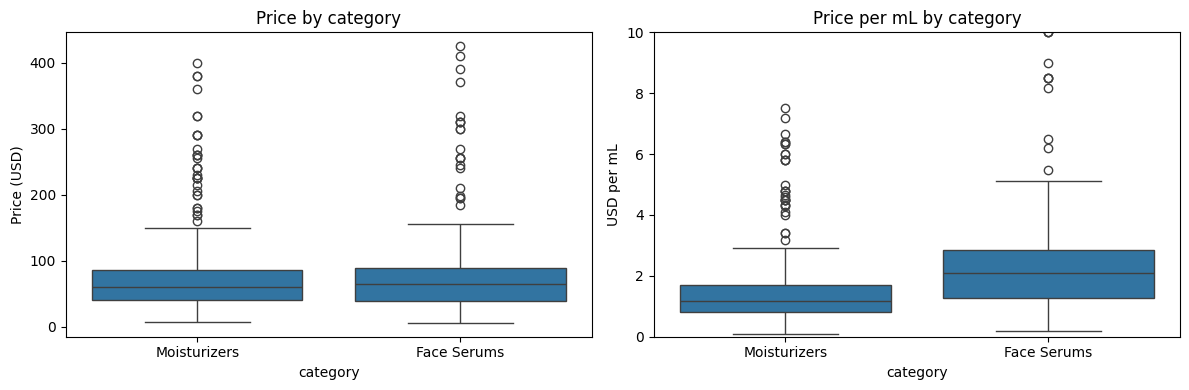

In [ ]:
# 1b. Price distribution: total price vs price per mL
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x="category", y="price_usd", ax=axes[0])
axes[0].set_title("Price by category")
axes[0].set_ylabel("Price (USD)")

sns.boxplot(data=df, x="category", y="price_per_ml", ax=axes[1])
axes[1].set_title("Price per mL by category")
axes[1].set_ylabel("USD per mL")
axes[1].set_ylim(0, 10)   # zoom in; a few extreme products go above $10/mL

plt.tight_layout()
plt.show()

### 1c. Rating distribution

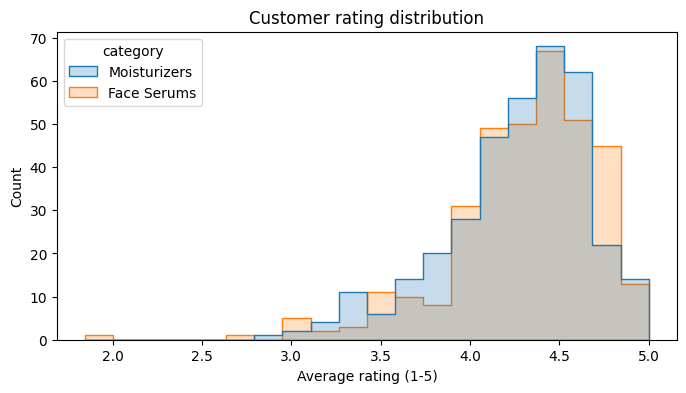

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
Face Serums,347.0,4.30,0.42,1.85,4.12,4.38,4.58,5.0
Moisturizers,355.0,4.27,0.40,2.94,4.06,4.33,4.54,5.0


In [ ]:
# 1c. Rating distribution
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="rating", hue="category", bins=20, element="step")
plt.title("Customer rating distribution")
plt.xlabel("Average rating (1-5)")
plt.show()

df.groupby("category")["rating"].describe().round(2)

### 1d. Does a higher price mean a higher rating?

> **Note:** the scatter plot and the price–rating correlation use all products. The price per mL correlation only uses products with a size listed in mL.

In [ ]:
# 1d. Does a higher price mean a higher rating?
fig = px.scatter(
    df, x="price_usd", y="rating", color="category",
    size="reviews", size_max=30, opacity=0.6,
    hover_data=["brand_name", "product_name", "reviews"],
    title="Price vs. rating (bubble size = number of reviews)",
    labels={"price_usd": "Price (USD)", "rating": "Average rating"},
)
fig.show()

# correlation between price and rating in each category
# spearman = based on ranks, so the few very expensive products don't dominate
df.groupby("category").apply(
    lambda g: pd.Series({
        "corr_price_rating": g["price_usd"].corr(g["rating"], method="spearman"),
        "corr_price_per_ml_rating": g["price_per_ml"].corr(g["rating"], method="spearman"),
    })
).round(3)

/tmp/ipykernel_618/565579647.py:13: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



,corr_price_rating,corr_price_per_ml_rating
category,,
Face Serums,0.100,0.057
Moisturizers,0.133,0.131


### 1e. Rating by price tier

/tmp/ipykernel_618/2443876676.py:2: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



,category,price_tier,products,median_price,mean_rating,median_rating,median_reviews,share_rated_4_plus
0,Face Serums,Affordable,117,29.0,4.25,4.29,265.0,0.78
1,Face Serums,Mid-range,114,65.0,4.39,4.44,263.5,0.89
2,Face Serums,Expensive,116,105.0,4.28,4.36,150.0,0.80
3,Moisturizers,Affordable,118,37.0,4.19,4.24,243.5,0.77
4,Moisturizers,Mid-range,121,60.0,4.29,4.40,224.0,0.85
5,Moisturizers,Expensive,116,111.0,4.33,4.39,101.5,0.80


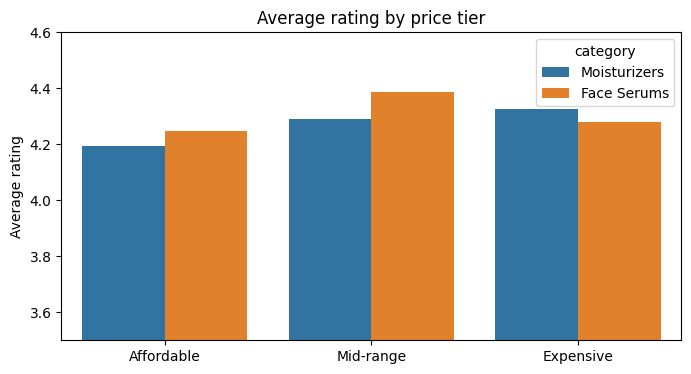

In [ ]:
# 1e. Rating by price tier
tier_summary = df.groupby(["category", "price_tier"]).agg(
    products=("product_id", "count"),
    median_price=("price_usd", "median"),
    mean_rating=("rating", "mean"),
    median_rating=("rating", "median"),
    median_reviews=("reviews", "median"),
    share_rated_4_plus=("rating", lambda x: (x >= 4).mean()),
).round(2).reset_index()
display(tier_summary)

plt.figure(figsize=(8, 4))
sns.barplot(data=df, x="price_tier", y="rating", hue="category", order=tier_order, errorbar=None)
plt.ylim(3.5, 4.6)
plt.title("Average rating by price tier")
plt.ylabel("Average rating")
plt.xlabel("")
plt.show()

### Q1 - Conclusion

**Prices vary widely across face serums and moisturizers, but customer ratings change very little with price.**

- **Prices:** The two categories have similar total prices (median 65 USD for serums, 60 USD for moisturizers) with a long right tail up to about 400 USD, so the means (76 and 79 USD) sit above the medians. Serums cost more per mL (median 2.10 vs. 1.18 USD per mL, based only on products listed in mL), which suggests they are typically sold in smaller sizes.
- **Ratings:** Ratings are high and similar in both categories (mean 4.30 vs. 4.27), with the middle half of products between roughly 4.1 and 4.6.
- **Price vs. rating:** The relationship is weak. Spearman correlations are 0.10 (serums) and 0.13 (moisturizers) for total price, and 0.06 and 0.13 for price per mL.
- **By price tier:** Affordable products are rated almost as well as expensive ones. For serums, the average rating is 4.25 (Affordable) vs. 4.28 (Expensive), and Mid-range is actually highest (4.39). For moisturizers, ratings rise slightly with price (4.19, 4.29, 4.33). About 77–78% of Affordable products are rated 4 or higher, compared with 80% of Expensive products.
- **Review volume:** Affordable products tend to have more reviews (median 265 vs. 150 for serums, 244 vs. 102 for moisturizers), so their ratings rest on more feedback.

**Implication:** Because price explains little of the variation in ratings, a lower price does not mean a lower-rated product. Ratings alone cannot tell us which products are good alternatives, since most products are rated well, so Q2 and Q3 add ingredient overlap and review counts to identify candidates.

*Note: these are correlations in a historical Sephora snapshot, not evidence that price causes differences in ratings.*

# Q2 - Shared Ingredients Between Affordable and Expensive Products

> Do some affordable products share many listed ingredients with more expensive products in the same category?


### 2a. Build every (Expensive, Affordable) pair inside the same category

We pair every Expensive product with every Affordable product **in the same category** (serum with serum, moisturizer with moisturizer). Pairs from the same brand are excluded, so that products from one brand's line are not counted as similar just because they share a formula. This gives 27,185 pairs from 232 Expensive and 235 Affordable products. Mid-range products are not used here.

In [ ]:
# 2a. Build every (Expensive, Affordable) pair inside the same category
cols = ["product_id", "brand_name", "product_name", "category",
        "price_usd", "price_per_ml", "rating", "reviews", "key_ingredients"]
expensive = df[df["price_tier"] == "Expensive"][cols]
affordable = df[df["price_tier"] == "Affordable"][cols]

# merging on category = every expensive product paired with every affordable product of the same type
pairs = expensive.merge(affordable, on="category", suffixes=("_exp", "_aff"))
pairs = pairs[pairs["brand_name_exp"] != pairs["brand_name_aff"]]   # compare different brands only

print("Expensive products:", len(expensive), "| Affordable products:", len(affordable))
print("Pairs compared:", len(pairs))

Expensive products: 232 | Affordable products: 235
Pairs compared: 27185


### 2b. Ingredient overlap for each pair
For each pair we compare the **key ingredients** (after removing the base ingredients) using two measures:

- `n_shared`: the number of key ingredients both products list.
- `jaccard`: shared ingredients divided by all distinct key ingredients in the two products (0 = nothing in common, 1 = identical lists).

Overlap is low for most pairs (average Jaccard 0.03 for serums and 0.05 for moisturizers), so only a small share of pairs have meaningful ingredient overlap.

In [ ]:
# 2b. Ingredient overlap for each pair
#   shared  = number of key ingredients both products list
#   jaccard = shared / all distinct key ingredients in the two products (0 = nothing in common, 1 = identical list)
pairs["shared_ingredients"] = pairs.apply(
    lambda r: r["key_ingredients_exp"] & r["key_ingredients_aff"], axis=1)
pairs["n_shared"] = pairs["shared_ingredients"].apply(len)
pairs["jaccard"] = pairs.apply(
    lambda r: r["n_shared"] / len(r["key_ingredients_exp"] | r["key_ingredients_aff"]), axis=1)

pairs.groupby("category")[["n_shared", "jaccard"]].describe().round(3).T

category        Face Serums  Moisturizers
n_shared count    13547.000     13638.000
         mean         1.599         3.159
         std          1.739         2.284
         min          0.000         0.000
         25%          0.000         1.000
         50%          1.000         3.000
         75%          2.000         4.000
         max         22.000        21.000
jaccard  count    13547.000     13638.000
         mean         0.031         0.049
         std          0.031         0.034
         min          0.000         0.000
         25%          0.000         0.024
         50%          0.026         0.043
         75%          0.047         0.068
         max          0.283         0.309

### 2c. For each affordable product: how close is its BEST match among expensive products?

For each Affordable product, we keep only its **closest Expensive match** (the pair with the highest Jaccard) and look at how close these best matches are. The red line marks the 0.15 threshold used for screening in Q3. The table counts, for each category, how many Affordable products have a best match above 0.15 and 0.20, or share at least 5 key ingredients.

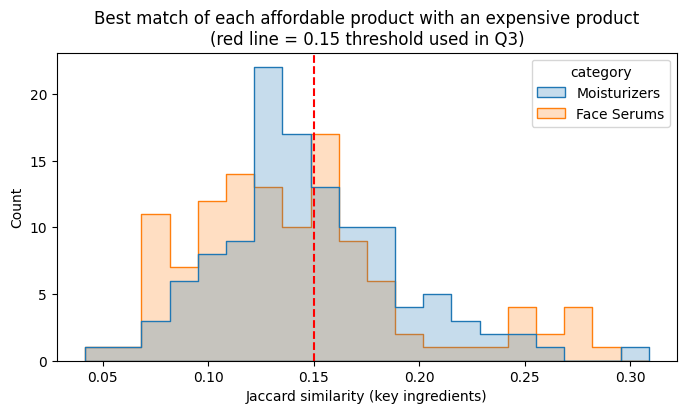

,affordable_products,median_best_jaccard,with_5plus_shared,with_jaccard_015,with_jaccard_020
category,,,,,
Face Serums,117,0.135,60,48,14
Moisturizers,118,0.143,104,49,14


In [ ]:
# 2c. For each affordable product: how close is its BEST match among expensive products?
best_match = (pairs.sort_values("jaccard", ascending=False)
                   .drop_duplicates("product_id_aff"))          # keep the top pair per affordable product

plt.figure(figsize=(8, 4))
sns.histplot(data=best_match, x="jaccard", hue="category", bins=20, element="step")
plt.axvline(0.15, color="red", linestyle="--")
plt.title("Best match of each affordable product with an expensive product\n(red line = 0.15 threshold used in Q3)")
plt.xlabel("Jaccard similarity (key ingredients)")
plt.show()

# how many affordable products have a 'close' expensive match?
best_match.groupby("category").agg(
    affordable_products=("product_id_aff", "count"),
    median_best_jaccard=("jaccard", "median"),
    with_5plus_shared=("n_shared", lambda x: (x >= 5).sum()),
    with_jaccard_015=("jaccard", lambda x: (x >= 0.15).sum()),
    with_jaccard_020=("jaccard", lambda x: (x >= 0.20).sum()),
).round(3)

### 2d. Pairs with the highest ingredient overlap

In [ ]:
# 2d. Pairs with the highest ingredient overlap
show_cols = ["category", "brand_name_exp", "product_name_exp", "price_usd_exp",
             "brand_name_aff", "product_name_aff", "price_usd_aff", "n_shared", "jaccard"]
pairs.sort_values("jaccard", ascending=False)[show_cols].head(15).round(3)

,category,brand_name_exp,product_name_exp,price_usd_exp,brand_name_aff,product_name_aff,price_usd_aff,n_shared,jaccard
13362,Moisturizers,FaceGym,Supreme Restructure Collagen-Boosting Cermide ...,120.0,Paula's Choice,Omega+ Complex Moisturizer,37.00,21,0.309
790,Face Serums,Algenist,AA (Alguronic Acid) Barrier Serum,85.0,The INKEY List,Ceramide Hydrating Night Treatment,15.99,15,0.283
11732,Face Serums,Drunk Elephant,Protini Powerpeptide Resurfacing Serum with La...,82.0,The Ordinary,"""Buffet"" + Copper Peptides 1%",30.90,22,0.278
18949,Face Serums,Lancôme,Clarifique Pro-Solution Brightening & Dark Spo...,85.0,IT Cosmetics,Bye Bye Dark Spots 4% Niacinamide Serum,29.00,8,0.276
11724,Face Serums,Drunk Elephant,Protini Powerpeptide Resurfacing Serum with La...,82.0,The Ordinary,Multi-Peptide + HA Serum,30.80,22,0.272
812,Face Serums,Algenist,AA (Alguronic Acid) Barrier Serum,85.0,The Ordinary,Amino Acids + B5,8.90,13,0.271
20861,Face Serums,Peter Thomas Roth,PRO Strength Lactic Pore Treatment,88.0,SEPHORA COLLECTION,Clarifying Serum,20.00,8,0.267
854,Moisturizers,Algenist,POWER Advanced Wrinkle Fighter Moisturizer,85.0,First Aid Beauty,Ultra Repair Cream Intense Hydration,38.00,8,0.258
20838,Face Serums,Peter Thomas Roth,PRO Strength Lactic Pore Treatment,88.0,Naturally Serious,Illumi-nation Anti-Fatigue Power Serum,39.00,8,0.258
810,Face Serums,Algenist,AA (Alguronic Acid) Barrier Serum,85.0,The Ordinary,Marine Hyaluronics,8.90,13,0.255


### 2e. Which ingredients are most often shared in the close pairs (jaccard >= 0.15)?

Among the close pairs (Jaccard of 0.15 or higher), this chart shows which key ingredients are shared most often, i.e., what drives the overlap between affordable and expensive products. Counts are by pair, so a product that appears in many close pairs contributes its ingredients many times.

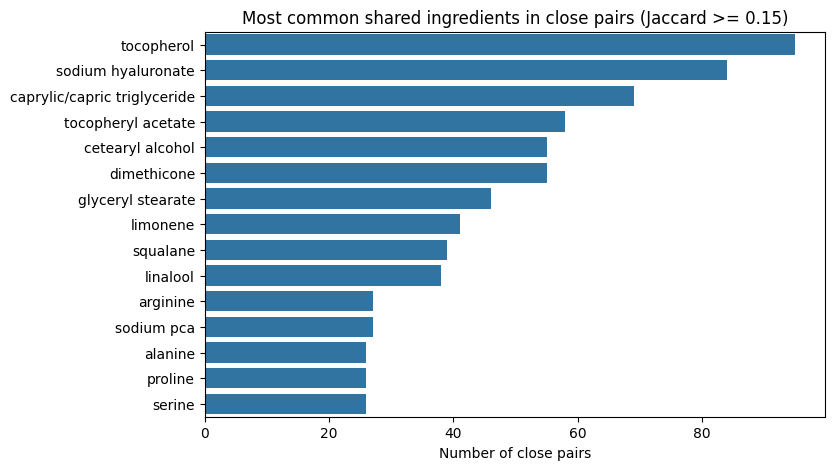

In [ ]:
# 2e. Which ingredients are most often shared in the close pairs (jaccard >= 0.15)?
close_pairs = pairs[pairs["jaccard"] >= 0.15]
top_shared = close_pairs["shared_ingredients"].explode().value_counts().head(15)

plt.figure(figsize=(8, 5))
sns.barplot(x=top_shared.values, y=top_shared.index)
plt.title("Most common shared ingredients in close pairs (Jaccard >= 0.15)")
plt.xlabel("Number of close pairs")
plt.ylabel("")
plt.show()

### Q2 - Conclusion

**Yes, some affordable products share many key ingredients with more expensive ones, but most pairs overlap very little.**

- **Overall overlap is low.** Across all 27,185 Expensive–Affordable pairs, the average Jaccard similarity is 0.03 for serums and 0.05 for moisturizers, and the typical pair shares only 1 (serums) to 3 (moisturizers) key ingredients. The highest pairs reach about 0.3.
- **A meaningful minority has a close match.** About 4 in 10 Affordable products (48 of 117 serums, 49 of 118 moisturizers) have an Expensive product with Jaccard of at least 0.15. Raising the bar to 0.20 leaves only about 1 in 8 (14 in each category).
- **Moisturizers overlap more than serums.** 104 of 118 Affordable moisturizers (88%) share at least 5 key ingredients with some Expensive product, compared with 60 of 117 serums (51%).
- **Close pairs exist across brands and price levels.** For example, Paula's Choice Omega+ Complex Moisturizer (37 USD) shares 21 key ingredients with FaceGym Supreme Restructure (120 USD), a Jaccard of 0.31.

**Implication:** Ingredient overlap can single out a limited set of promising affordable candidates, but it does not apply to every expensive product. Q3 narrows these pairs further using the 0.15 similarity threshold, at least 5 shared key ingredients, ratings, and review counts.

*Note: the 0.15 threshold is our own choice. Base ingredients are excluded, which lowers all Jaccard values, so they should be read as relative rather than absolute similarity. Overlap also ignores ingredient concentration, so it shows that products list similar ingredients, not that they work the same way.*

# Q3 - Find Alternative products

> Which lower-priced products could be reasonable alternative candidates based on ingredient overlap, ratings, review counts, and price?



### 3a. Apply the screening rules

We keep an (Expensive, Affordable) pair as an alternative candidate only if it passes all of these rules:

- Ingredient overlap: Jaccard of at least 0.15 and at least 5 shared key ingredients.
- Rating: the affordable product is rated at least 4.0 and no more than 0.2 below the expensive product.
- Reliability: the affordable product has at least 50 reviews.

For each pair that passes, we also compute the savings versus the expensive product (in USD and as a percentage). In total, 103 pairs pass, covering 51 distinct affordable products and 65 expensive products.

In [ ]:
# 3a. Apply the screening rules
MIN_JACCARD, MIN_SHARED, MIN_RATING, MIN_REVIEWS = 0.15, 5, 4.0, 50

candidates = pairs[
    (pairs["jaccard"] >= MIN_JACCARD)
    & (pairs["n_shared"] >= MIN_SHARED)
    & (pairs["rating_aff"] >= MIN_RATING)
    & (pairs["rating_aff"] >= pairs["rating_exp"] - 0.2)
    & (pairs["reviews_aff"] >= MIN_REVIEWS)
].copy()

candidates["savings_usd"] = candidates["price_usd_exp"] - candidates["price_usd_aff"]
candidates["savings_pct"] = candidates["savings_usd"] / candidates["price_usd_exp"]
candidates["savings_per_ml_pct"] = 1 - candidates["price_per_ml_aff"] / candidates["price_per_ml_exp"]

print("Pairs passing all rules:", len(candidates))
print("Unique affordable candidates:", candidates["product_id_aff"].nunique())
print("Expensive products with at least one candidate:", candidates["product_id_exp"].nunique())
candidates.groupby("category").agg(
    pairs=("jaccard", "count"),
    unique_candidates=("product_id_aff", "nunique"),
    median_savings_pct=("savings_pct", "median"),
).round(2)

Pairs passing all rules: 103
Unique affordable candidates: 51
Expensive products with at least one candidate: 65


,pairs,unique_candidates,median_savings_pct
category,,,
Face Serums,44,25,0.67
Moisturizers,59,26,0.74


### 3b. Rank candidates: overlap first, then rating, then savings

Candidate pairs are ranked by ingredient overlap first, then by the affordable product's rating, then by savings. The table shows the top 20. The same affordable product can appear more than once, because it may be a close match for several expensive products.

In [ ]:
# 3b. Rank candidates: overlap first, then rating, then savings
result_cols = ["category", "brand_name_exp", "product_name_exp", "price_usd_exp", "rating_exp",
               "brand_name_aff", "product_name_aff", "price_usd_aff", "rating_aff", "reviews_aff",
               "n_shared", "jaccard", "savings_pct"]

top_candidates = candidates.sort_values(["jaccard", "rating_aff", "savings_pct"], ascending=False)
top_candidates[result_cols].head(20).round(2)

,category,brand_name_exp,product_name_exp,price_usd_exp,rating_exp,brand_name_aff,product_name_aff,price_usd_aff,rating_aff,reviews_aff,n_shared,jaccard,savings_pct
13362,Moisturizers,FaceGym,Supreme Restructure Collagen-Boosting Cermide ...,120.0,4.44,Paula's Choice,Omega+ Complex Moisturizer,37.00,4.33,64.0,21,0.31,0.69
790,Face Serums,Algenist,AA (Alguronic Acid) Barrier Serum,85.0,3.97,The INKEY List,Ceramide Hydrating Night Treatment,15.99,4.29,307.0,15,0.28,0.81
11732,Face Serums,Drunk Elephant,Protini Powerpeptide Resurfacing Serum with La...,82.0,4.36,The Ordinary,"""Buffet"" + Copper Peptides 1%",30.90,4.18,255.0,22,0.28,0.62
18949,Face Serums,Lancôme,Clarifique Pro-Solution Brightening & Dark Spo...,85.0,4.40,IT Cosmetics,Bye Bye Dark Spots 4% Niacinamide Serum,29.00,4.33,271.0,8,0.28,0.66
812,Face Serums,Algenist,AA (Alguronic Acid) Barrier Serum,85.0,3.97,The Ordinary,Amino Acids + B5,8.90,4.41,228.0,13,0.27,0.90
20838,Face Serums,Peter Thomas Roth,PRO Strength Lactic Pore Treatment,88.0,4.58,Naturally Serious,Illumi-nation Anti-Fatigue Power Serum,39.00,4.67,88.0,8,0.26,0.56
854,Moisturizers,Algenist,POWER Advanced Wrinkle Fighter Moisturizer,85.0,4.18,First Aid Beauty,Ultra Repair Cream Intense Hydration,38.00,4.52,7539.0,8,0.26,0.55
810,Face Serums,Algenist,AA (Alguronic Acid) Barrier Serum,85.0,3.97,The Ordinary,Marine Hyaluronics,8.90,4.21,244.0,13,0.25,0.90
775,Face Serums,Algenist,AA (Alguronic Acid) Barrier Serum,85.0,3.97,Summer Fridays,Dream Oasis Deep Hydration Serum,44.00,4.74,485.0,15,0.25,0.48
22319,Moisturizers,Shiseido,Benefiance Wrinkle Smoothing Cream,75.0,4.60,WASO,SHIKULIME Mega Hydrating Moisturizer,36.00,4.66,539.0,16,0.24,0.52


### 3c. Best expensive -> affordable match for each expensive product (one row per luxury product)

To get one answer per expensive product, we keep only the top-ranked candidate for each of them. This gives one row for each of the 65 expensive products that have at least one candidate.

In [ ]:
# 3c. Best expensive -> affordable match for each expensive product (one row per luxury product)
best_per_luxury = top_candidates.drop_duplicates("product_id_exp")
best_per_luxury[result_cols].round(2)

,category,brand_name_exp,product_name_exp,price_usd_exp,rating_exp,brand_name_aff,product_name_aff,price_usd_aff,rating_aff,reviews_aff,n_shared,jaccard,savings_pct
13362,Moisturizers,FaceGym,Supreme Restructure Collagen-Boosting Cermide ...,120.0,4.44,Paula's Choice,Omega+ Complex Moisturizer,37.00,4.33,64.0,21,0.31,0.69
790,Face Serums,Algenist,AA (Alguronic Acid) Barrier Serum,85.0,3.97,The INKEY List,Ceramide Hydrating Night Treatment,15.99,4.29,307.0,15,0.28,0.81
11732,Face Serums,Drunk Elephant,Protini Powerpeptide Resurfacing Serum with La...,82.0,4.36,The Ordinary,"""Buffet"" + Copper Peptides 1%",30.90,4.18,255.0,22,0.28,0.62
18949,Face Serums,Lancôme,Clarifique Pro-Solution Brightening & Dark Spo...,85.0,4.40,IT Cosmetics,Bye Bye Dark Spots 4% Niacinamide Serum,29.00,4.33,271.0,8,0.28,0.66
20838,Face Serums,Peter Thomas Roth,PRO Strength Lactic Pore Treatment,88.0,4.58,Naturally Serious,Illumi-nation Anti-Fatigue Power Serum,39.00,4.67,88.0,8,0.26,0.56
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5521,Face Serums,Dermalogica,Sound Sleep Cocoon Night Gel-Cream,89.0,4.18,WASO,YUZU-C Glow-On Shot Serum,45.00,4.42,359.0,7,0.15,0.49
23263,Face Serums,Shiseido,White Lucent Illuminating Micro-Spot Serum,185.0,3.00,WASO,YUZU-C Glow-On Shot Serum,45.00,4.42,359.0,10,0.15,0.76
15659,Face Serums,Kate Somerville,DeliKate Recovery Serum,98.0,4.64,LAWLESS,Set The Stage Hydrating Primer Serum,32.00,4.60,251.0,6,0.15,0.67
385,Moisturizers,Algenist,Overnight Restorative Cream,94.0,4.38,First Aid Beauty,Ultra Repair Cream Intense Hydration,38.00,4.52,7539.0,6,0.15,0.60


### 3d. Reusable function: look up alternatives for any expensive product by (part of) its name

`find_alternatives()` returns the top candidates for any expensive product, found by typing part of its name (e.g., "Protini"), so alternatives can be looked up without re-running the analysis.

In [ ]:
# 3d. Reusable function: look up alternatives for any expensive product by (part of) its name
def find_alternatives(name, n=5):
    result = top_candidates[top_candidates["product_name_exp"].str.contains(name, case=False, regex=False)]
    if result.empty:
        print("No candidates found for:", name)
        return None
    return result[result_cols].head(n).round(2)

find_alternatives("Protini")

,category,brand_name_exp,product_name_exp,price_usd_exp,rating_exp,brand_name_aff,product_name_aff,price_usd_aff,rating_aff,reviews_aff,n_shared,jaccard,savings_pct
11732,Face Serums,Drunk Elephant,Protini Powerpeptide Resurfacing Serum with La...,82.0,4.36,The Ordinary,"""Buffet"" + Copper Peptides 1%",30.90,4.18,255.0,22,0.28,0.62
11699,Face Serums,Drunk Elephant,Protini Powerpeptide Resurfacing Serum with La...,82.0,4.36,Summer Fridays,Dream Oasis Deep Hydration Serum,44.00,4.74,485.0,19,0.24,0.46
11736,Face Serums,Drunk Elephant,Protini Powerpeptide Resurfacing Serum with La...,82.0,4.36,The Ordinary,Amino Acids + B5,8.90,4.41,228.0,16,0.23,0.89
11714,Face Serums,Drunk Elephant,Protini Powerpeptide Resurfacing Serum with La...,82.0,4.36,The INKEY List,Ceramide Hydrating Night Treatment,15.99,4.29,307.0,17,0.22,0.80
11734,Face Serums,Drunk Elephant,Protini Powerpeptide Resurfacing Serum with La...,82.0,4.36,The Ordinary,Marine Hyaluronics,8.90,4.21,244.0,15,0.20,0.89


### 3e. Comparison table for one showcase luxury product
As a worked example, we compare one expensive product with its top five candidates. The showcase product is the most-reviewed expensive product that has at least five candidates (Drunk Elephant Protini Powerpeptide Resurfacing Serum). The table and charts show price, price per mL, rating, reviews, shared ingredients, and savings, and the last line lists the key ingredients shared with the top candidate.

> **Note:** price per mL is only available for products with a size listed in mL; it would show as missing (`NaN`) for products listed in other units.

,brand,product,role,price_usd,price_per_ml,rating,reviews,shared_key_ingredients,jaccard,savings_pct
0,Drunk Elephant,Protini Powerpeptide Resurfacing Serum with La...,High-priced,82.00,2.733333,4.3619,713.0,NaN,NaN,NaN
1,The Ordinary,"""Buffet"" + Copper Peptides 1%",Candidate,30.90,1.030000,4.1804,255.0,22.0,0.28,62.0
2,Summer Fridays,Dream Oasis Deep Hydration Serum,Candidate,44.00,1.466667,4.7361,485.0,19.0,0.24,46.0
3,The Ordinary,Amino Acids + B5,Candidate,8.90,0.296667,4.4123,228.0,16.0,0.23,89.0
4,The INKEY List,Ceramide Hydrating Night Treatment,Candidate,15.99,0.533000,4.2899,307.0,17.0,0.22,80.0
5,The Ordinary,Marine Hyaluronics,Candidate,8.90,0.296667,4.2090,244.0,15.0,0.20,89.0


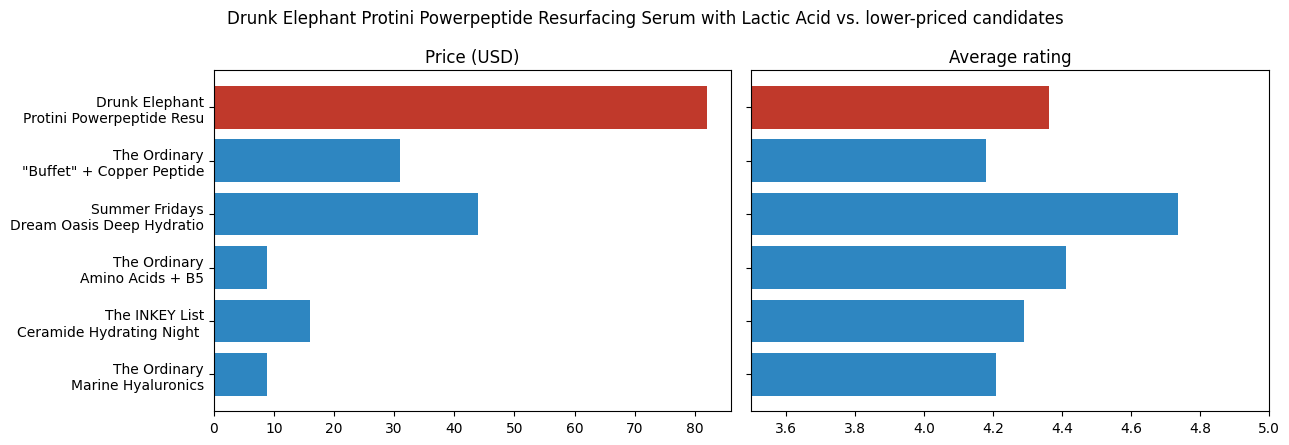

Shared with top candidate: ['alanine', 'arginine', 'aspartic acid', 'chlorphenesin', 'glycine', 'histidine', 'hydroxypropyl cyclodextrin', 'isoleucine', 'palmitoyl tetrapeptide-7', 'palmitoyl tripeptide-1', 'palmitoyl tripeptide-38', 'pca', 'phenylalanine', 'polysorbate 20', 'proline', 'serine', 'sodium hyaluronate', 'sodium hyaluronate crosspolymer', 'sodium lactate', 'sodium pca', 'threonine', 'valine']


In [ ]:
# 3e. Comparison table for one showcase luxury product
# = the most-reviewed expensive product that has at least 5 candidates
n_candidates = candidates["product_id_exp"].value_counts()
many = candidates[candidates["product_id_exp"].isin(n_candidates[n_candidates >= 5].index)]
showcase_id = many.sort_values("reviews_exp", ascending=False)["product_id_exp"].iloc[0]
show = top_candidates[top_candidates["product_id_exp"] == showcase_id].head(5)

luxury_row = df[df["product_id"] == showcase_id].iloc[0]
table = pd.DataFrame({
    "brand": [luxury_row["brand_name"]] + show["brand_name_aff"].tolist(),
    "product": [luxury_row["product_name"]] + show["product_name_aff"].tolist(),
    "role": ["High-priced"] + ["Candidate"] * len(show),
    "price_usd": [luxury_row["price_usd"]] + show["price_usd_aff"].tolist(),
    "price_per_ml": [luxury_row["price_per_ml"]] + show["price_per_ml_aff"].tolist(),
    "rating": [luxury_row["rating"]] + show["rating_aff"].tolist(),
    "reviews": [luxury_row["reviews"]] + show["reviews_aff"].tolist(),
    "shared_key_ingredients": [None] + show["n_shared"].tolist(),
    "jaccard": [None] + show["jaccard"].round(2).tolist(),
    "savings_pct": [None] + (show["savings_pct"] * 100).round(0).tolist(),
})
display(table)

# chart: price and rating side by side
table["label"] = table["brand"] + "\n" + table["product"].str[:25]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
colors = ["#c0392b"] + ["#2e86c1"] * len(show)
axes[0].barh(table["label"], table["price_usd"], color=colors)
axes[0].set_title("Price (USD)")
axes[0].invert_yaxis()
axes[1].barh(table["label"], table["rating"], color=colors)
axes[1].set_xlim(3.5, 5)
axes[1].set_title("Average rating")
axes[1].invert_yaxis()
axes[1].set_yticklabels([])
plt.suptitle(f"{luxury_row['brand_name']} {luxury_row['product_name']} vs. lower-priced candidates")
plt.tight_layout()
plt.show()

# which key ingredients does the top candidate share with the luxury product?
print("Shared with top candidate:", sorted(show.iloc[0]["shared_ingredients"]))

### 3f. Overall view: every candidate pair - how much cheaper and how similar?
Each point is one candidate pair, plotted by ingredient similarity (x) and savings versus the expensive product (y). Point size shows the number of reviews of the affordable product. Pairs in the upper right are both highly similar and much cheaper.

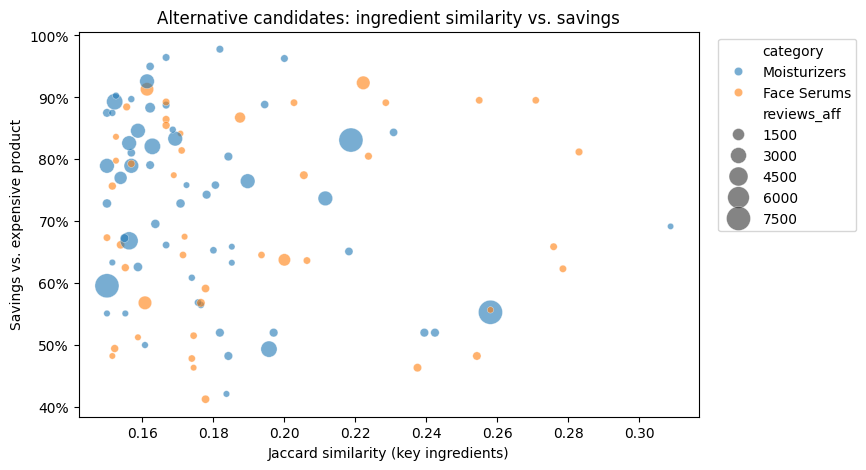

In [ ]:
# 3f. Overall view: every candidate pair - how much cheaper and how similar?
plt.figure(figsize=(8, 5))
sns.scatterplot(data=candidates, x="jaccard", y="savings_pct", hue="category",
                size="reviews_aff", sizes=(20, 300), alpha=0.6)
plt.title("Alternative candidates: ingredient similarity vs. savings")
plt.xlabel("Jaccard similarity (key ingredients)")
plt.ylabel("Savings vs. expensive product")
plt.gca().yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

###4. Predictive Modeling:
Can a product's formula and listing details predict (a) whether it sits in the Expensive price tier and (b) whether customers rate it highly (4.5+)?

In [ ]:
# 4a. Build model features
import json, os, joblib
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)
from sklearn.inspection import permutation_importance

def has_any(ingredients, words):
    return int(any(w in ing for ing in ingredients for w in words))

ACTIVES = {
    "has_niacinamide":  ["niacinamide"],
    "has_retinoid":     ["retinol", "retinal", "retinyl", "bakuchiol"],
    "has_peptide":      ["peptide"],
    "has_vitamin_c":    ["ascorbic", "ascorbyl"],
    "has_hyaluronic":   ["hyaluron"],
    "has_ceramide":     ["ceramide"],
    "has_exfoliant":    ["glycolic", "lactic acid", "salicylic", "mandelic"],
    "has_squalane":     ["squalane"],
    "has_fragrance":    ["parfum", "fragrance", "linalool", "limonene"],
}

model_df = df.copy()
for col, words in ACTIVES.items():
    model_df[col] = model_df["key_ingredients"].apply(lambda s: has_any(s, words))
model_df["n_extracts"] = model_df["ingredient_set"].apply(lambda s: sum("extract" in i for i in s))

hl = model_df["highlights"].fillna("").str.lower()
model_df["is_vegan"] = hl.str.contains("vegan").astype(int)
model_df["is_clean"] = hl.str.contains("clean at sephora").astype(int)
model_df["is_fragrance_free"] = hl.str.contains("fragrance free").astype(int)

model_df["is_serum"] = (model_df["category"] == "Face Serums").astype(int)
model_df["log_reviews"] = np.log1p(model_df["reviews"])
model_df["log_loves"] = np.log1p(model_df["loves_count"])
for c in ["new", "limited_edition", "online_only", "sephora_exclusive"]:
    model_df[c] = model_df[c].fillna(0).astype(int)

# targets
model_df["is_expensive"] = (model_df["price_tier"] == "Expensive").astype(int)
model_df["is_high_rated"] = (model_df["rating"] >= 4.5).astype(int)

COMMON = (["is_serum", "size_ml", "child_count", "n_ingredients", "n_extracts",
           "log_reviews", "log_loves", "new", "limited_edition", "online_only", "sephora_exclusive",
           "is_vegan", "is_clean", "is_fragrance_free"] + list(ACTIVES))

TARGETS = {
    "is_expensive":  {"label": "Expensive tier", "features": COMMON + ["rating"]},
    "is_high_rated": {"label": "High rating (4.5+)", "features": COMMON + ["price_usd"]},
}

print("Rows:", len(model_df))
model_df[["is_expensive", "is_high_rated"]].mean().round(3).to_frame("share_positive")

Rows: 702


,share_positive
is_expensive,0.330
is_high_rated,0.333


### Logistic Regression and Random Forest (trained)


In [ ]:
# 4b. Train and tune Logistic Regression and Random Forest
RANDOM_STATE = 42
os.makedirs("models", exist_ok=True)
os.makedirs("data", exist_ok=True)

def make_pipeline(model, features):
    pre = ColumnTransformer([("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), features)])
    return Pipeline([("prep", pre), ("model", model)])

MODELS = {
    "Logistic Regression": (LogisticRegression(max_iter=2000),
                            {"model__C": [0.01, 0.1, 1, 10]}),
    "Random Forest":       (RandomForestClassifier(random_state=RANDOM_STATE),
                            {"model__n_estimators": [200, 400], "model__max_depth": [None, 5, 10],
                             "model__min_samples_leaf": [1, 3, 5]}),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results, roc_data, cm_data, best_params, splits = [], {}, {}, {}, {}

for target, spec in TARGETS.items():
    X, y = model_df[spec["features"]], model_df[target]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
    splits[target] = (X_te, y_te)
    for name, (model, grid) in MODELS.items():
        search = GridSearchCV(make_pipeline(model, spec["features"]), grid, cv=cv, scoring="roc_auc", n_jobs=-1)
        search.fit(X_tr, y_tr)
        best = search.best_estimator_
        proba = best.predict_proba(X_te)[:, 1]
        pred = (proba >= 0.5).astype(int)
        results.append({
            "target": target, "model": name,
            "cv_auc": search.best_score_,
            "test_auc": roc_auc_score(y_te, proba),
            "accuracy": accuracy_score(y_te, pred),
            "precision": precision_score(y_te, pred, zero_division=0),
            "recall": recall_score(y_te, pred),
            "f1": f1_score(y_te, pred),
        })
        fpr, tpr, _ = roc_curve(y_te, proba)
        roc_data.setdefault(target, {})[name] = {"fpr": fpr.round(4).tolist(), "tpr": tpr.round(4).tolist()}
        cm_data.setdefault(target, {})[name] = confusion_matrix(y_te, pred).tolist()
        best_params.setdefault(target, {})[name] = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
        joblib.dump(best, f"models/{target}__{name.lower().replace(' ', '_')}.joblib")

results_df = pd.DataFrame(results)
results_df.round(3)

,target,model,cv_auc,test_auc,accuracy,precision,recall,f1
0,is_expensive,Logistic Regression,0.792,0.707,0.730,0.636,0.447,0.525
1,is_expensive,Random Forest,0.829,0.725,0.738,0.656,0.447,0.532
2,is_high_rated,Logistic Regression,0.645,0.597,0.652,0.333,0.043,0.075
3,is_high_rated,Random Forest,0.703,0.661,0.681,0.600,0.128,0.211


### Model Comparison


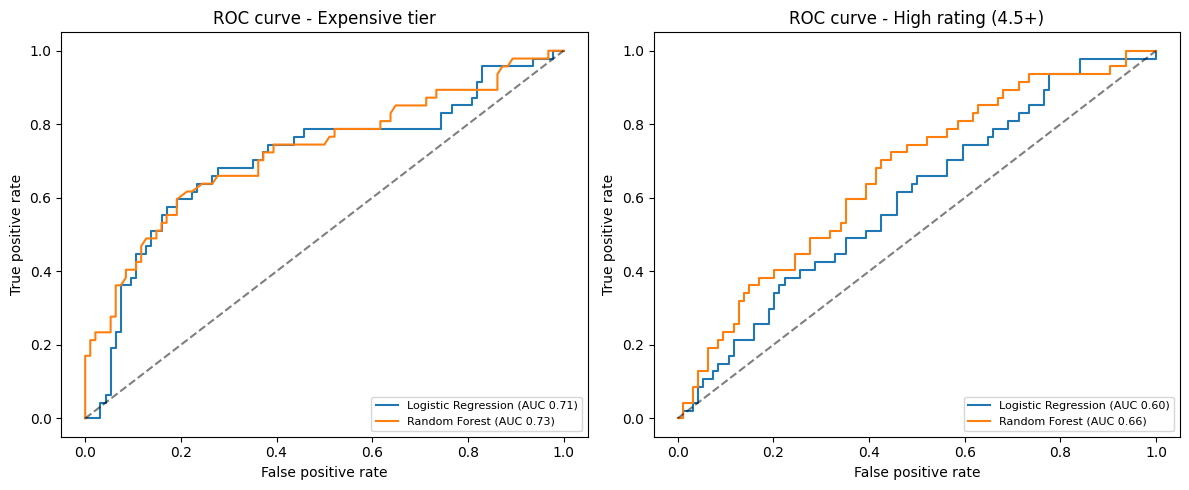

is_expensive


,C,max_depth,min_samples_leaf,n_estimators
Logistic Regression,1.0,NaN,NaN,NaN
Random Forest,NaN,NaN,1.0,400.0


is_high_rated


,C,max_depth,min_samples_leaf,n_estimators
Logistic Regression,0.01,NaN,NaN,NaN
Random Forest,NaN,NaN,5.0,200.0


In [ ]:
# 4c. Model comparison: ROC curves and best hyperparameters
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (target, spec) in zip(axes, TARGETS.items()):
    for name, pts in roc_data[target].items():
        auc = results_df.query("target == @target and model == @name")["test_auc"].iloc[0]
        ax.plot(pts["fpr"], pts["tpr"], label=f"{name} (AUC {auc:.2f})")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
    ax.set_title(f"ROC curve - {spec['label']}")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

for target in TARGETS:
    print(target)
    display(pd.DataFrame(best_params[target]).T)

### Permutation

In [ ]:
# 4d. Permutation importance for the best model of each target
importance = {}
best_models = results_df.loc[results_df.groupby("target")["test_auc"].idxmax(), ["target", "model"]]
for _, row in best_models.iterrows():
    X_te, y_te = splits[row["target"]]
    pipe = joblib.load(f"models/{row['target']}__{row['model'].lower().replace(' ', '_')}.joblib")
    imp = permutation_importance(pipe, X_te, y_te, scoring="roc_auc", n_repeats=20, random_state=RANDOM_STATE)
    s = pd.Series(imp.importances_mean, index=X_te.columns).sort_values(ascending=False)
    importance[row["target"]] = {"model": row["model"], "importance": s.round(4).to_dict()}
    print(f"{row['target']} - best model: {row['model']}")
    display(s.head(8).round(3).to_frame("AUC drop"))

is_expensive - best model: Random Forest


,AUC drop
has_fragrance,0.048
sephora_exclusive,0.040
child_count,0.029
n_ingredients,0.029
is_clean,0.019
n_extracts,0.017
rating,0.014
log_loves,0.012


is_high_rated - best model: Random Forest


,AUC drop
log_reviews,0.050
log_loves,0.050
price_usd,0.023
new,0.020
online_only,0.013
has_retinoid,0.011
has_ceramide,0.010
n_ingredients,0.007


### Export Results for Streamlit

In [ ]:
# 4e. Export results for the Streamlit app
feature_stats = {}
all_feats = sorted(set(TARGETS["is_expensive"]["features"]) | set(TARGETS["is_high_rated"]["features"]))
for f in all_feats:
    col = model_df[f]
    feature_stats[f] = {"mean": float(col.mean()), "min": float(col.min()), "max": float(col.max()),
                        "median": float(col.median())}

export = {
    "targets": {t: {"label": s["label"], "features": s["features"],
                    "positive_rate": float(model_df[t].mean())} for t, s in TARGETS.items()},
    "results": results_df.to_dict(orient="records"),
    "best_params": best_params,
    "roc": roc_data,
    "confusion": cm_data,
    "importance": importance,
    "feature_stats": feature_stats,
    "n_train": int(len(model_df) * 0.8), "n_test": int(len(model_df) - int(len(model_df) * 0.8)),
}
with open("models/model_results.json", "w") as f:
    json.dump(export, f, indent=1, default=str)

keep = ["product_id", "brand_name", "product_name", "category", "price_usd", "size_ml", "price_per_ml",
        "rating", "reviews", "loves_count", "price_tier", "n_ingredients"]
out = model_df[keep].copy()
out["key_ingredients"] = model_df["key_ingredients"].apply(lambda s: "; ".join(sorted(s)))
out.to_csv("data/products_clean.csv", index=False)

alt = top_candidates[result_cols + ["savings_usd"]].copy()
alt["shared_ingredients"] = top_candidates["shared_ingredients"].apply(lambda s: "; ".join(sorted(s)))
alt.to_csv("data/alternatives.csv", index=False)

print(sorted(os.listdir("models")))
print(sorted(os.listdir("data")))

['is_expensive__logistic_regression.joblib', 'is_expensive__random_forest.joblib', 'is_high_rated__logistic_regression.joblib', 'is_high_rated__random_forest.joblib', 'model_results.json']
['alternatives.csv', 'products_clean.csv']


### Conclusion

**Reasonable lower-priced alternatives exist for roughly 3 in 10 expensive products, with large savings and similar ratings.**

- **Coverage:** After applying all screening rules (Jaccard of at least 0.15, at least 5 shared key ingredients, a rating of at least 4.0 and within 0.2 of the expensive product, and at least 50 reviews), 103 pairs remain. They cover **65 of the 232 expensive products (about 28%)** and 51 distinct affordable products (25 serums and 26 moisturizers).
- **Savings:** The typical candidate costs far less than the product it replaces: the median saving is 67% for serums and 74% for moisturizers.
- **Strong examples:**
  - Drunk Elephant Protini (82 USD, rating 4.36) → The Ordinary "Buffet" + Copper Peptides (30.90 USD, rating 4.18, 22 shared key ingredients, 62% cheaper), or Summer Fridays Dream Oasis (44 USD, rating 4.74, 19 shared, 46% cheaper).
  - Algenist AA Barrier Serum (85 USD) → The Ordinary Amino Acids + B5 (8.90 USD, rating 4.41, 13 shared, 90% cheaper).
- **A few affordable products cover many expensive ones.** 103 pairs come from only 51 affordable products, so a small set of products (e.g., several from The Ordinary) are close matches for multiple luxury items.

**Implication:** For a shopper or a retailer's recommendation feature, ingredient overlap combined with ratings and review counts can surface a short, credible list of cheaper options, but not for every product. Most expensive products have no candidate that passes all the rules.


**A product's formula and listing details predict its price tier only moderately, and predict top ratings weakly. This supports the Q1–Q3 finding that luxury prices are not explained by what is in the bottle.**

- **Expensive tier:** Random Forest beats Logistic Regression (test ROC AUC 0.73 vs. 0.71; CV AUC 0.83 vs. 0.79) with 74% accuracy, versus 67% for always guessing "not expensive". It finds fewer than half of the expensive products (recall 0.45), so many luxury products look like cheaper ones on every attribute except price and brand.
- **What separates expensive products:** fragrance ingredients (46% of fragranced products are Expensive vs. 24% of unfragranced), longer ingredient lists (median 42 vs. 35), and *not* being a Sephora exclusive or "Clean at Sephora" product.
- **High rating (4.5+):** Harder to predict. Random Forest reaches a test AUC of 0.66 vs. 0.60 for Logistic Regression. Review and love counts matter most; price ranks only third.
- **Model choice:** Random Forest wins on both targets, which points to non-linear effects that a linear model misses.

**Implication:** If expensive products cannot be told apart from cheaper ones by their formula, and ratings barely follow price, a well-reviewed affordable product with overlapping key ingredients (Q3) is a reasonable alternative to try first.

*Note: with about 700 products and a 141-product test set, metrics shift by a few points with a different split. The 0.5 threshold favors precision; a lower threshold would raise recall.*

*Note: candidates are possible alternatives, not proven equivalents. Overlap is based on listed ingredient names only, without concentrations or formula quality, and the thresholds are our own choices, so stricter rules would shorten the list. Savings are based on total price, not size, and the data is a historical snapshot rather than current pricing.*

#